# AirLens India

Group 6 uses five pollutant readings, the city, and the date to estimate daily AQI.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [3]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

## A first look at the data

We check which cities are covered, how much data is missing, and whether any rows are duplicated.

In [4]:
from pathlib import Path

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

df = pd.read_csv(project_root / "data" / "city_day.csv")
df.head()

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [5]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Cities:", df["City"].nunique())

Rows: 29531
Columns: 16
Cities: 26


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  object 
 1   Date        29531 non-null  object 
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-null  object 
dtypes: float64(13), object(3)
memory usage: 3.6+ MB


In [7]:
df.describe()

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI
count,24933.000000,18391.000000,25949.000000,25946.000000,25346.000000,19203.000000,27472.000000,25677.000000,25509.000000,23908.000000,21490.000000,11422.000000,24850.000000
mean,67.450578,118.127103,17.574730,28.560659,32.309123,23.483476,2.248598,14.531977,34.491430,3.280840,8.700972,3.070128,166.463581
std,64.661449,90.605110,22.785846,24.474746,31.646011,25.684275,6.962884,18.133775,21.694928,15.811136,19.969164,6.323247,140.696585
min,0.040000,0.010000,0.020000,0.010000,0.000000,0.010000,0.000000,0.010000,0.010000,0.000000,0.000000,0.000000,13.000000
25%,28.820000,56.255000,5.630000,11.750000,12.820000,8.580000,0.510000,5.670000,18.860000,0.120000,0.600000,0.140000,81.000000
50%,48.570000,95.680000,9.890000,21.690000,23.520000,15.850000,0.890000,9.160000,30.840000,1.070000,2.970000,0.980000,118.000000
75%,80.590000,149.745000,19.950000,37.620000,40.127500,30.020000,1.450000,15.220000,45.570000,3.080000,9.150000,3.350000,208.000000
max,949.990000,1000.000000,390.680000,362.210000,467.630000,352.890000,175.810000,193.860000,257.730000,455.030000,454.850000,170.370000,2049.000000


In [8]:
df.isnull().sum()

City              0
Date              0
PM2.5          4598
PM10          11140
NO             3582
NO2            3585
NOx            4185
NH3           10328
CO             2059
SO2            3854
O3             4022
Benzene        5623
Toluene        8041
Xylene        18109
AQI            4681
AQI_Bucket     4681
dtype: int64

In [9]:
missing = df.isnull().mean() * 100
missing.sort_values(ascending=False).round(2)

Xylene        61.32
PM10          37.72
NH3           34.97
Toluene       27.23
Benzene       19.04
AQI           15.85
AQI_Bucket    15.85
PM2.5         15.57
NOx           14.17
O3            13.62
SO2           13.05
NO2           12.14
NO            12.13
CO             6.97
City           0.00
Date           0.00
dtype: float64

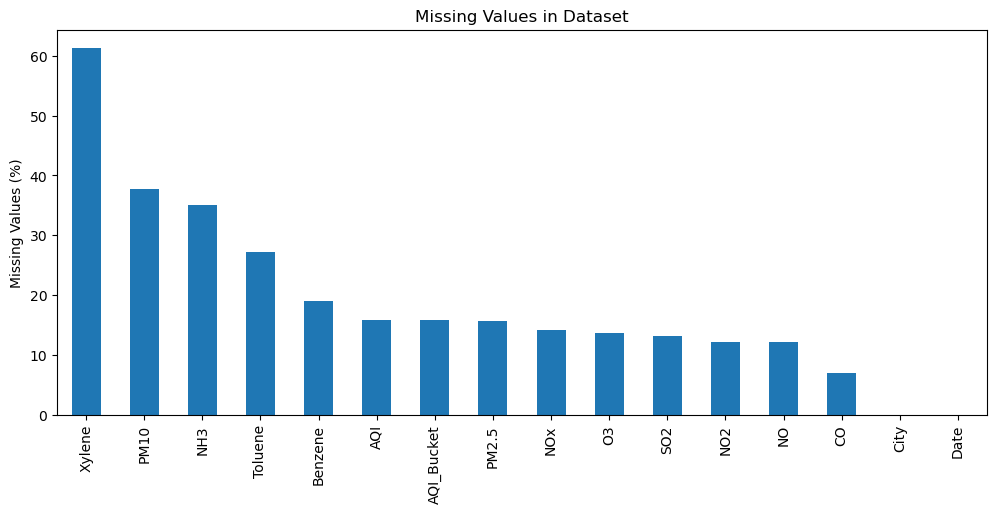

In [10]:
plt.figure(figsize=(12, 5))
missing.sort_values(ascending=False).plot(kind="bar")
plt.ylabel("Missing Values (%)")
plt.title("Missing Values in Dataset")
plt.show()

In [11]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


## Cleaning the data

We remove duplicates and drop rows without an AQI because they have no target to learn from. We keep AQI values from 0 to 500 so the model uses the same scale as the app.

In [12]:
pollutants = ["PM2.5", "PM10", "NO2", "SO2", "CO"]

columns = ["City", "Date"] + pollutants + ["AQI"]

df = df[columns].copy()
df.head()

,City,Date,PM2.5,PM10,NO2,SO2,CO,AQI
0,Ahmedabad,2015-01-01,NaN,NaN,18.22,27.64,0.92,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,15.69,24.55,0.97,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,19.30,29.07,17.40,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,18.48,18.59,1.70,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,21.42,39.33,22.10,NaN


In [13]:
df = df.drop_duplicates()
df = df.dropna(subset=["AQI"]).copy()

print("Remaining records:", len(df))

Remaining records: 24850


In [14]:
print("Minimum AQI:", df["AQI"].min())
print("Maximum AQI:", df["AQI"].max())
print("AQI above 500:", (df["AQI"] > 500).sum())

Minimum AQI: 13.0
Maximum AQI: 2049.0
AQI above 500: 543


In [15]:
df = df[df["AQI"].between(0, 500)].copy()

print("Remaining records:", len(df))

Remaining records: 24307


In [16]:
df[pollutants].isnull().sum()

PM2.5     671
PM10     6695
NO2       390
SO2       597
CO        436
dtype: int64

## Getting features from the date

We extract the year, month, day of the month, and day of the week so the models can pick up seasonal changes and weekly patterns.

In [17]:
df["Date"] = pd.to_datetime(df["Date"])

df["Date"].head()

28   2015-01-29
29   2015-01-30
34   2015-02-04
35   2015-02-05
36   2015-02-06
Name: Date, dtype: datetime64[ns]

In [18]:
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day
df["DayOfWeek"] = df["Date"].dt.dayofweek

In [19]:
df[["Date", "Year", "Month", "Day", "DayOfWeek"]].head()

,Date,Year,Month,Day,DayOfWeek
28,2015-01-29,2015,1,29,3
29,2015-01-30,2015,1,30,4
34,2015-02-04,2015,2,4,2
35,2015-02-05,2015,2,5,3
36,2015-02-06,2015,2,6,4


## How AQI varies

We compare AQI across cities and months, then look at how the five pollutant readings relate to AQI.

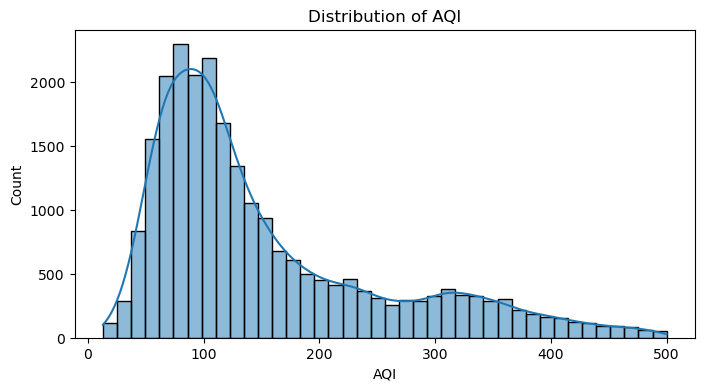

In [20]:
plt.figure(figsize=(8, 4))
sns.histplot(df["AQI"], bins=40, kde=True)
plt.title("Distribution of AQI")
plt.show()

In [21]:
city_aqi = df.groupby("City")["AQI"].mean()
city_aqi.sort_values(ascending=False)

City
Ahmedabad             291.719089
Delhi                 252.105074
Patna                 235.552999
Gurugram              219.407407
Lucknow               215.193823
Talcher               170.828530
Jorapokhar            155.585079
Brajrajnagar          150.280505
Kolkata               140.566313
Guwahati              137.040568
Jaipur                133.679159
Bhopal                132.827338
Amritsar              117.821747
Visakhapatnam         117.269855
Chennai               114.502654
Hyderabad             108.155650
Mumbai                105.352258
Kochi                 104.284810
Chandigarh             96.498328
Amaravati              95.299643
Bengaluru              94.318325
Ernakulam              92.359477
Thiruvananthapuram     75.878327
Coimbatore             73.023256
Shillong               53.795122
Aizawl                 34.765766
Name: AQI, dtype: float64

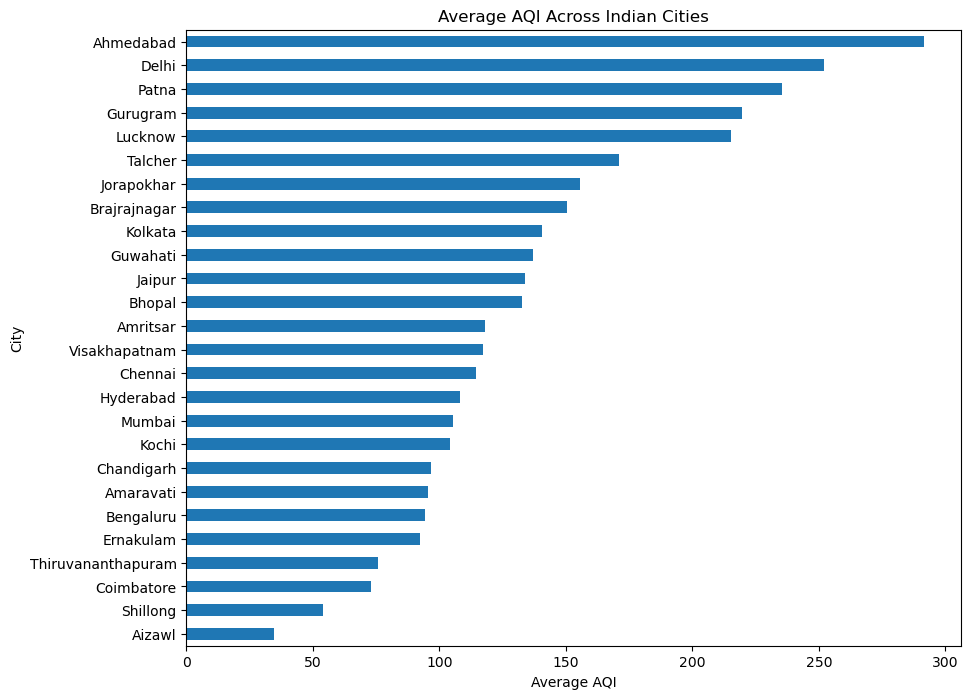

In [22]:
plt.figure(figsize=(10, 8))
city_aqi.sort_values().plot(kind="barh")
plt.xlabel("Average AQI")
plt.title("Average AQI Across Indian Cities")
plt.show()

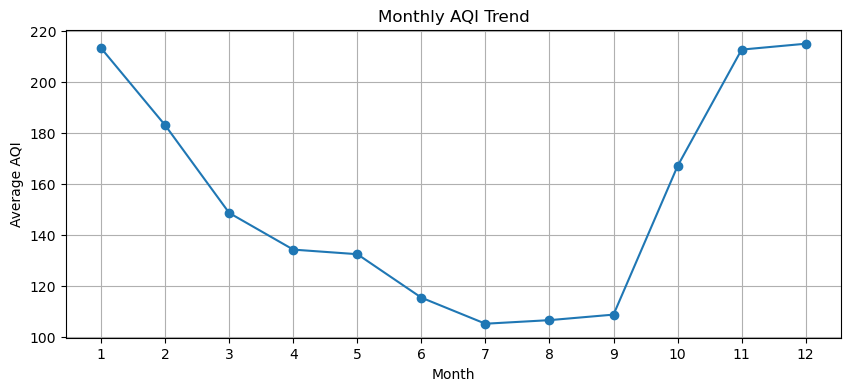

In [23]:
monthly_aqi = df.groupby("Month")["AQI"].mean()

monthly_aqi.plot(marker="o", figsize=(10, 4))
plt.xticks(range(1, 13))
plt.ylabel("Average AQI")
plt.title("Monthly AQI Trend")
plt.grid()
plt.show()

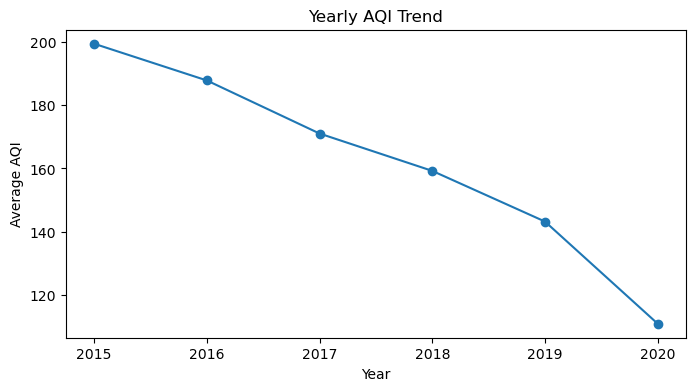

In [24]:
df.groupby("Year")["AQI"].mean().plot(
    kind="line", marker="o", figsize=(8, 4)
)

plt.title("Yearly AQI Trend")
plt.ylabel("Average AQI")
plt.show()

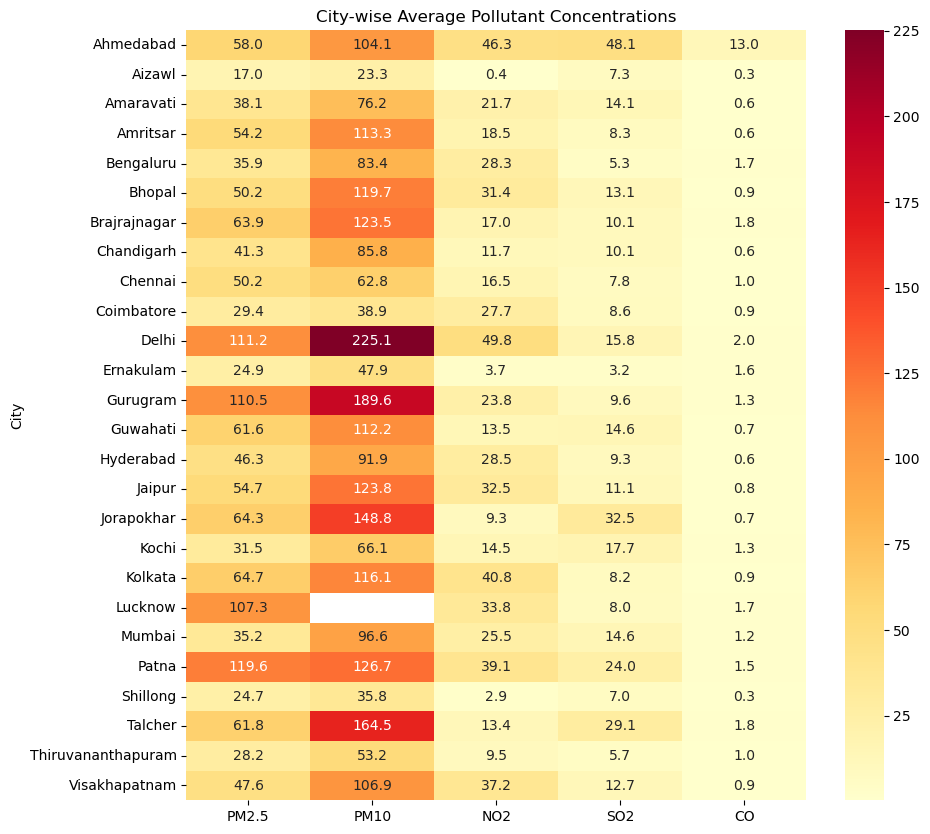

In [25]:
plt.figure(figsize=(10, 10))
sns.heatmap(
    df.groupby("City")[pollutants].mean(),
    annot=True, fmt=".1f", cmap="YlOrRd"
)
plt.title("City-wise Average Pollutant Concentrations")
plt.show()

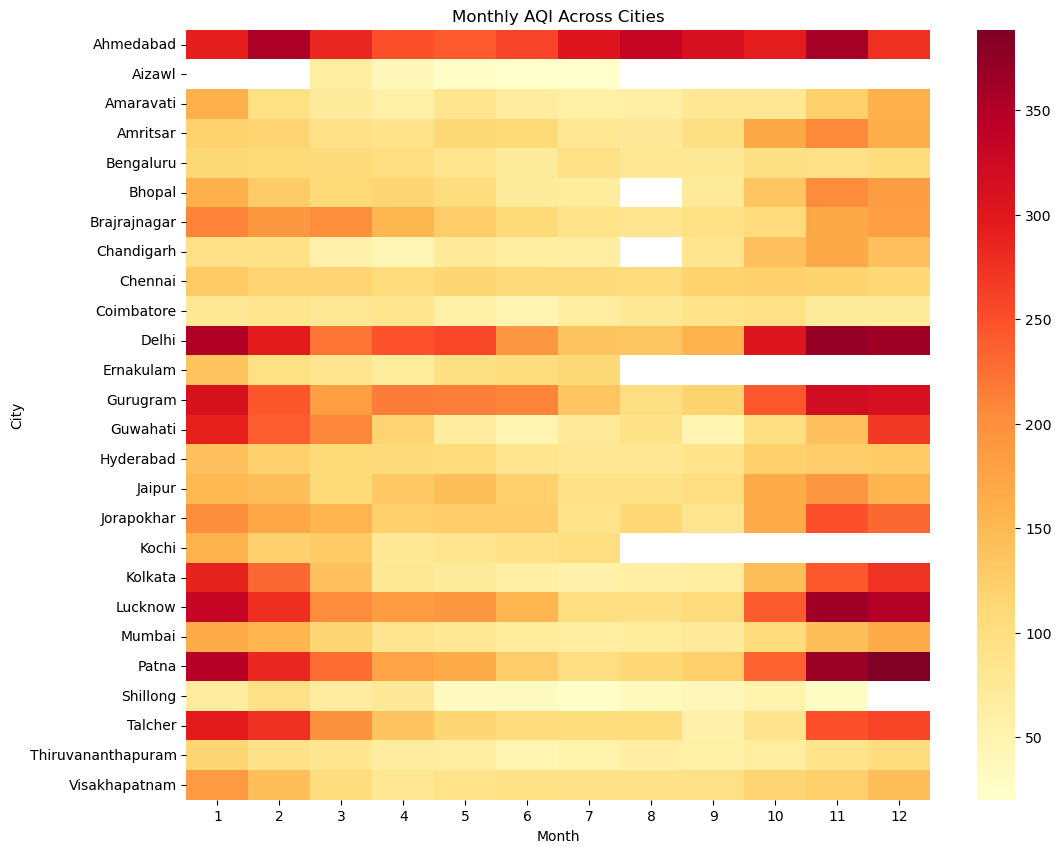

In [26]:
monthly_city = df.pivot_table(
    values="AQI", index="City",
    columns="Month", aggfunc="mean"
)

plt.figure(figsize=(12, 10))
sns.heatmap(monthly_city, cmap="YlOrRd")
plt.title("Monthly AQI Across Cities")
plt.show()

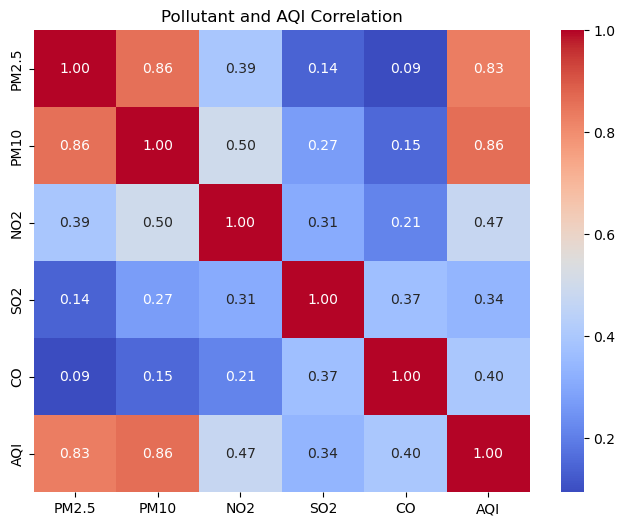

In [27]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    df[pollutants + ["AQI"]].corr(),
    annot=True, cmap="coolwarm", fmt=".2f"
)
plt.title("Pollutant and AQI Correlation")
plt.show()

## Splitting by date

We train on the earliest dates, validate on the next set of dates, and test on the latest dates. This keeps later observations out of model selection.

In [28]:
features = ["City"] + pollutants + [
    "Year", "Month", "Day", "DayOfWeek"
]

X = df[features]
y = df["AQI"]

In [29]:
df = df.sort_values("Date")
dates = df["Date"].unique()

cutoff1 = dates[int(len(dates) * 0.70)]
cutoff2 = dates[int(len(dates) * 0.85)]

In [30]:
train = df[df["Date"] < cutoff1]

val = df[(df["Date"] >= cutoff1) &
         (df["Date"] < cutoff2)]

test = df[df["Date"] >= cutoff2]

In [31]:
X_train, y_train = train[features], train["AQI"]
X_val, y_val = val[features], val["AQI"]
X_test, y_test = test[features], test["AQI"]

In [32]:
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (12122, 10)
Validation: (5273, 10)
Testing: (6912, 10)


## Preparing the inputs

We fill missing pollutant readings with medians learned from the fitting data. The median is less sensitive to spikes. We give each city its own indicator column so the model sees no ranking between cities.

In [33]:
numerical_features = pollutants + [
    "Year", "Month", "Day", "DayOfWeek"
]

categorical_features = ["City"]

In [34]:
numerical_transformer = SimpleImputer(
    strategy="median"
)

In [35]:
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

In [36]:
preprocessor = ColumnTransformer([
    ("num", numerical_transformer, numerical_features),
    ("city", categorical_transformer, categorical_features)
])

## Training the models

Linear Regression gives us a baseline. Random Forest can capture more complex relationships between the readings and AQI.

In [37]:
from sklearn.base import clone

lr = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", LinearRegression())
])

In [38]:
lr.fit(X_train, y_train)

print("Linear Regression trained successfully")

Linear Regression trained successfully


In [39]:
rf = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestRegressor(
        n_estimators=80, max_depth=12,
        random_state=42, n_jobs=-1
    ))
])

In [40]:
rf.fit(X_train, y_train)

print("Random Forest trained successfully")

Random Forest trained successfully


In [41]:
imputer = lr.named_steps["preprocessor"].named_transformers_["num"]

pd.Series(
    imputer.statistics_,
    index=numerical_features
)

PM2.5          54.79
PM10          103.91
NO2            24.24
SO2             7.88
CO              0.99
Year         2017.00
Month           7.00
Day            16.00
DayOfWeek       3.00
dtype: float64

## Comparing the models

We pick the model with the lowest validation RMSE, then refit both models on the training and validation data. We compare MAE, MSE, RMSE, and R² on the later test dates.

In [42]:
def evaluate(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "MSE": mean_squared_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    }

In [43]:
lr_val = np.clip(lr.predict(X_val), 0, 500)
rf_val = np.clip(rf.predict(X_val), 0, 500)

In [44]:
validation_results = pd.DataFrame({
    "Linear Regression": evaluate(y_val, lr_val),
    "Random Forest": evaluate(y_val, rf_val)
}).T

validation_results.round(4)

,MAE,MSE,RMSE,R2
Linear Regression,25.5540,1465.4764,38.2815,0.8618
Random Forest,19.2383,948.1098,30.7914,0.9106


In [45]:
best_name = validation_results["RMSE"].idxmin()

print("Best Model:", best_name)

Best Model: Random Forest


In [46]:
development = pd.concat([train, val])

X_dev = development[features]
y_dev = development["AQI"]

lr.fit(X_dev, y_dev)
rf.fit(X_dev, y_dev)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  SimpleImputer(strategy='median'),
                                                  ['PM2.5', 'PM10', 'NO2',
                                                   'SO2', 'CO', 'Year', 'Month',
                                                   'Day', 'DayOfWeek']),
                                                 ('city',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['City'])])),
                ('model',
                 RandomForestRegressor(max_depth=12, n_estimators=80, n_jobs=-1,
                                       random_state=42))])

In [47]:
lr_pred = np.clip(lr.predict(X_test), 0, 500)
rf_pred = np.clip(rf.predict(X_test), 0, 500)

In [48]:
results = pd.DataFrame({
    "Linear Regression": evaluate(y_test, lr_pred),
    "Random Forest": evaluate(y_test, rf_pred)
}).T

results.round(4)

,MAE,MSE,RMSE,R2
Linear Regression,21.7566,962.2052,31.0194,0.8632
Random Forest,16.7518,621.4131,24.9282,0.9117


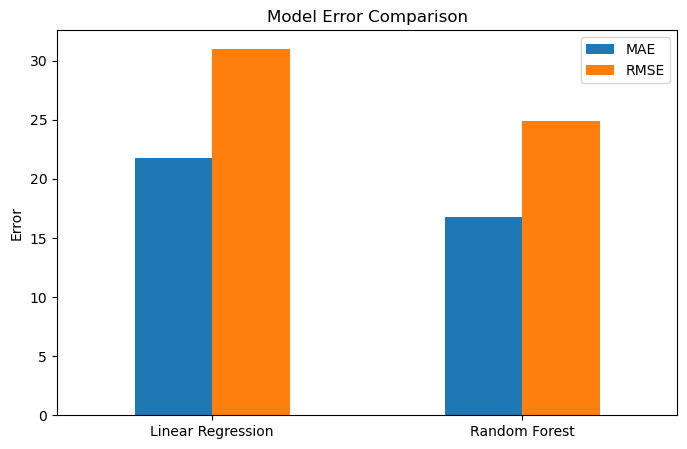

In [49]:
results[["MAE", "RMSE"]].plot(
    kind="bar", figsize=(8, 5)
)

plt.title("Model Error Comparison")
plt.ylabel("Error")
plt.xticks(rotation=0)
plt.show()

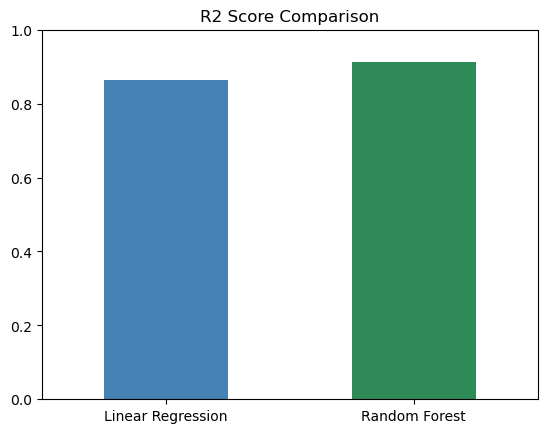

In [50]:
results["R2"].plot(
    kind="bar", color=["steelblue", "seagreen"]
)

plt.title("R2 Score Comparison")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.show()

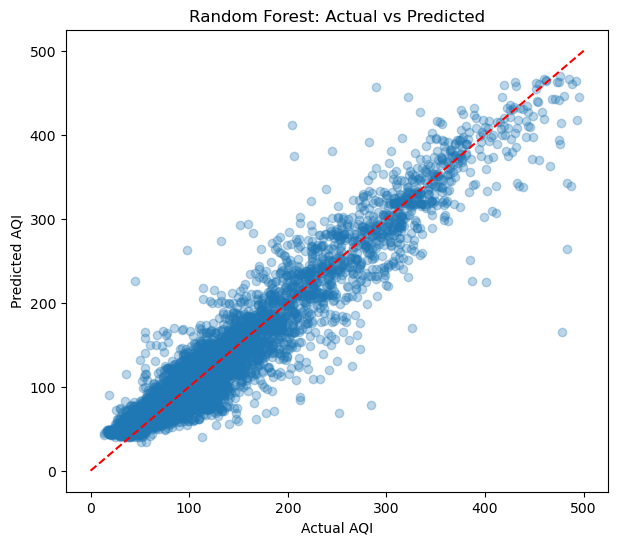

In [51]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, rf_pred, alpha=0.3)
plt.plot([0, 500], [0, 500], "r--")
plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.title("Random Forest: Actual vs Predicted")
plt.show()

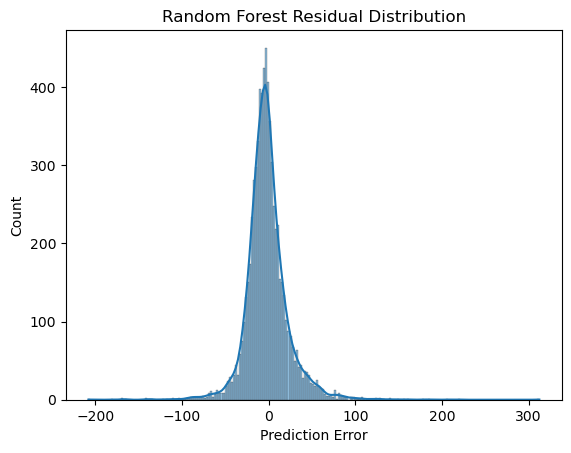

In [52]:
residuals = y_test - rf_pred

sns.histplot(residuals, kde=True)
plt.title("Random Forest Residual Distribution")
plt.xlabel("Prediction Error")
plt.show()

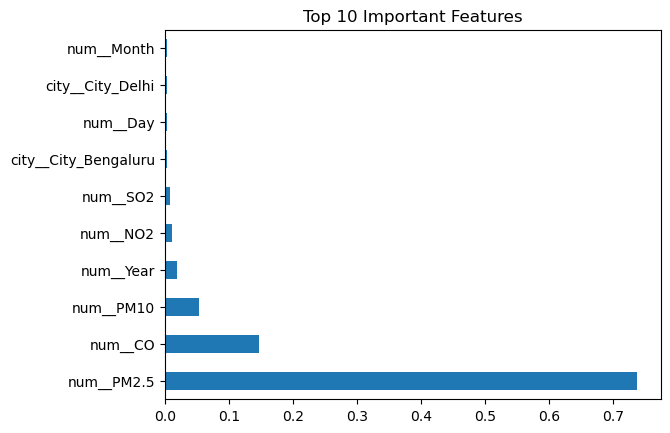

In [53]:
names = rf.named_steps["preprocessor"].get_feature_names_out()
importance = rf.named_steps["model"].feature_importances_

pd.Series(importance, index=names).nlargest(10).plot.barh()

plt.title("Top 10 Important Features")
plt.show()

## Result and Streamlit export

Random Forest had the lower test MAE (16.75 vs. 21.76) and higher R² (0.912 vs. 0.863). We refit it on all cleaned rows and save it for the app, which displays both the score and its AQI category.

In [54]:
def aqi_category(aqi):
    if aqi <= 50:
        return "Good"
    elif aqi <= 100:
        return "Satisfactory"
    elif aqi <= 200:
        return "Moderate"
    elif aqi <= 300:
        return "Poor"
    elif aqi <= 400:
        return "Very Poor"
    else:
        return "Severe"

In [55]:
models = {
    "Linear Regression": lr,
    "Random Forest": rf
}

best_model = clone(models[best_name])
best_model.fit(df[features], df["AQI"])

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  SimpleImputer(strategy='median'),
                                                  ['PM2.5', 'PM10', 'NO2',
                                                   'SO2', 'CO', 'Year', 'Month',
                                                   'Day', 'DayOfWeek']),
                                                 ('city',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['City'])])),
                ('model',
                 RandomForestRegressor(max_depth=12, n_estimators=80, n_jobs=-1,
                                       random_state=42))])

In [56]:
sample = pd.DataFrame([[
    "Mumbai", 75, 120, 35, 12, 1.2,
    2020, 1, 15, 2
]], columns=features)

sample

,City,PM2.5,PM10,NO2,SO2,CO,Year,Month,Day,DayOfWeek
0,Mumbai,75,120,35,12,1.2,2020,1,15,2


In [57]:
prediction = best_model.predict(sample)[0]
prediction = int(round(np.clip(prediction, 0, 500)))

print("Predicted AQI:", prediction)
print("Category:", aqi_category(prediction))

Predicted AQI: 154
Category: Moderate


In [58]:
joblib.dump({
    "model": best_model,
    "cities": sorted(df["City"].unique().tolist()),
    "features": features,
    "model_name": best_name
}, project_root / "models" / "aqi_model.pkl", compress=3)

print("Model saved successfully")

Model saved successfully


In [59]:
saved = joblib.load(project_root / "models" / "aqi_model.pkl")

print("Model:", saved["model_name"])
print("Supported Cities:", len(saved["cities"]))
print("Prediction:", saved["model"].predict(sample)[0])

Model: Random Forest
Supported Cities: 26
Prediction: 154.03144939023912
